# Examine In primum caput Ecclesiastes

This notebook evaluates the hold-out work "X2_ecclesiastes" against the shared hexameter test corpus to assess its linguistic compatibility with **H** (Hildebert) and with the other comparison profiles.

## Approach

We use stylometric analysis (Lambda-G) on 100 random ~750-token samples from *In primum caput Ecclesiastes*. The shared logistic regression model calibrated on the known-authorship hexameter training corpus converts raw LambdaG scores into calibrated probabilities.

*De ordine mundi* (`X_ordine`) remains fully excluded from training, test splitting, and calibration. It is reintroduced only at the application stage as an **analysis-only candidate**, so that it can appear in the same comparative ranking without entering the reference pool for the other candidates.

## Stages

1. **Setup** — Load the shared test corpus, the two hold-out corpora, and the trained model
2. **Evaluation vs H** — Run 100 parallel comparisons with Hildebert
3. **Comparative evaluation** — Run 100 comparisons against each background candidate and against *De ordine* as an analysis-only candidate
4. **Visualization** — Inspect raw scores, calibrated probabilities, and the comparative ranking


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import ray
from tqdm import tqdm
from typing import Any

from sentence_corpora import TwoLevelCorpus
from sentence_corpora.lambdag.av import LambdaGAV

import mpl_fontkit as fk

# Set up Roboto Condensed font
fk.install("Roboto Condensed")

# Set seaborn theme
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 300,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.unicode_minus": False,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    },
)

Font name: `Roboto Condensed`


In [3]:
# ---------------------------------------------------------
# Common files produced by the general calibration pipeline
# ---------------------------------------------------------

GENERAL_DIR = Path("..").resolve()

TEST_CORPUS_PATH = GENERAL_DIR / "test_corpus.pkl"
ECCLESIASTES_CORPUS_PATH = GENERAL_DIR / "ecclesiastes_corpus.pkl"
ORDINE_CORPUS_PATH = GENERAL_DIR / "ordine_corpus.pkl"
MODEL_PATH = GENERAL_DIR / "logistic_regression_model_uncorrected.pkl"

# Check that the required general files exist
for path in [
    TEST_CORPUS_PATH,
    ECCLESIASTES_CORPUS_PATH,
    ORDINE_CORPUS_PATH,
    MODEL_PATH,
]:
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

print(f"General analysis directory: {GENERAL_DIR}")

# Load corpora
test_corpus = TwoLevelCorpus.from_pickle(
    str(TEST_CORPUS_PATH)
)

ecclesiastes_corpus = TwoLevelCorpus.from_pickle(
    str(ECCLESIASTES_CORPUS_PATH)
)

ordine_corpus = TwoLevelCorpus.from_pickle(
    str(ORDINE_CORPUS_PATH)
)

# Sanity checks: both uncertain works must remain holdouts from test_corpus
test_authors = set(test_corpus.get_unique_values("author"))
assert "X2" not in test_authors, "X2_ecclesiastes must not be present in test_corpus"
assert "X" not in test_authors, "X_ordine must not be present in test_corpus"

ordine_authors = set(ordine_corpus.get_unique_values("author"))
assert ordine_authors == {"X"}, (
    f"Expected ordine_corpus to contain only author X, found: {ordine_authors}"
)

print(
    f"In primum caput Ecclesiastes: "
    f"{len(ecclesiastes_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in ecclesiastes_corpus)} tokens"
)

print(
    f"De ordine mundi: "
    f"{len(ordine_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in ordine_corpus)} tokens"
)

print(
    f"Test corpus: {len(test_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in test_corpus)} tokens"
)

print(
    f"Test corpus authors: "
    f"{test_corpus.get_unique_values('author')}"
)

# Analysis-only corpus used when De ordine (X) is itself the candidate.
# X remains excluded from the reference pool in every other comparison.
test_plus_ordine = type(test_corpus)(
    list(test_corpus) + list(ordine_corpus),
    levels=test_corpus.levels,
)


General analysis directory: /Users/martinapaccara/Documents/Documenti/Università/POST-LAUREA/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Lexical analysis
In primum caput Ecclesiastes: 79 sentences, 1079 tokens
De ordine mundi: 281 sentences, 4084 tokens
Test corpus: 14066 sentences, 245249 tokens
Test corpus authors: ['AI', 'AeC', 'AeP', 'B', 'BC', 'DC', 'E', 'FB', 'GAp', 'GAr', 'GC', 'GM', 'GP', 'GVS', 'GiP', 'H', 'HA', 'HP', 'IH', 'II', 'M', 'NLC', 'OM', 'OSE', 'RC', 'RT', 'SG', 'U1', 'U10', 'U11', 'U2', 'U3', 'U4', 'U5', 'U6', 'U7', 'U8', 'U9']


In [4]:
# Sampling function
def sample_corpus_to_token_count(corpus, target_tokens: int, rng: Any):
    """Sample sentences from corpus until we reach approximately target_tokens.

    Shuffles sentences and adds them until we exceed target_tokens.
    """
    sentences = list(corpus)
    total_tokens = sum(len(s.text.split()) for s in sentences)

    if total_tokens <= target_tokens:
        raise ValueError(
            f"Corpus has only {total_tokens} tokens, which is less than target {target_tokens}"
        )

    shuffled = list(sentences)
    rng.shuffle(shuffled)

    sampled = []
    current_tokens = 0
    for s in shuffled:
        sampled.append(s)
        current_tokens += len(s.text.split())
        if current_tokens >= target_tokens:
            break

    return type(corpus)(sampled, levels=corpus.levels)

In [5]:
# Initialize Ray
ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

2026-09-14 09:30:51,480	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


/opt/anaconda3/lib/python3.11/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


In [6]:
test_corpus.stats()

Author      Works    Sentences    Tokens    Mean Len
--------  -------  -----------  --------  ----------
AI              1          470     9,861        21
AeC             2          509    14,745        29
AeP             1          190     5,806        30.6
B               1          111     1,991        17.9
BC              1          830     6,994         8.4
DC              1          398     6,449        16.2
E               1          160     3,326        20.8
FB              1          775    10,684        13.8
GAp             1          423     6,004        14.2
GAr             1          532    11,367        21.4
GC              1          612    12,123        19.8
GM              1          184     3,379        18.4
GP              1          516    14,417        27.9
GVS             1          400     4,958        12.4
GiP             1          327     5,741        17.6
H               2          202     2,829        14
HA              1          372     5,049        13.6

### In primum caput Ecclesiastes vs Hildebert

In [8]:
# Define the evaluation function for Ray
@ray.remote
def run_ecclesiastes_evaluation(
    seed: int,
    target_tokens: int = 750,
) -> dict:
    """Run a single AV evaluation: In primum caput Ecclesiastes vs author H."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    # Sample ~750 tokens from In primum caput Ecclesiastes as the unknown (q_corpus)
    q_corpus = sample_corpus_to_token_count(ecclesiastes_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity="H",
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=2000,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "score": result["score"],
        "corrected_score_sqrt": result["corrected_score_sqrt"],
        "corrected_score_hapax": result["corrected_score_hapax"],
        "n_unknown": result["unknown_sentences_used"],
        "unknown_tokens": result["unknown_tokens_used"],
    }

In [9]:
# Create 100 evaluation tasks
master_rng = np.random.default_rng(42)
TARGET_TOKENS = 750
N_EVALUATIONS = 100

print(f"Creating {N_EVALUATIONS} evaluation tasks...")
tasks = []
for i in range(N_EVALUATIONS):
    seed = master_rng.integers(0, 2**32 - 1)
    tasks.append(run_ecclesiastes_evaluation.remote(seed, TARGET_TOKENS))
print(f"✓ Created {len(tasks)} tasks")

Creating 100 evaluation tasks...
✓ Created 100 tasks


In [10]:
# Execute all tasks in parallel with progress bar
print("\nExecuting tasks in parallel...")
results = []

for _ in tqdm(range(len(tasks)), desc="Evaluations"):
    ready, _ = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    results.append(result)
    tasks.remove(ready[0])

print(f"✓ Completed {len(results)} evaluations")
ray.shutdown()


Executing tasks in parallel...


Evaluations:   0%|                                     | 0/100 [00:00<?, ?it/s](pid=1360) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=1360)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=1360) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=1360)   from pandas.core import (
Evaluations: 100%|███████████████████████████| 100/100 [00:33<00:00,  3.03it/s]
(pid=1355) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see 

✓ Completed 100 evaluations


In [11]:
# Convert to DataFrame
df = pd.DataFrame(results)

print("=== Score Statistics ===")
print(df[["score", "corrected_score_sqrt", "corrected_score_hapax"]].describe())

print(f"\nUnknown token stats:")
print(f"  Mean: {df['unknown_tokens'].mean():.0f}")
print(f"  Min:  {df['unknown_tokens'].min()}")
print(f"  Max:  {df['unknown_tokens'].max()}")

=== Score Statistics ===
            score  corrected_score_sqrt  corrected_score_hapax
count  100.000000            100.000000             100.000000
mean    22.761526              0.826168               1.762200
std     30.505819              1.107452               2.416293
min    -52.836344             -1.912804              -4.224138
25%      8.139179              0.297032               0.599979
50%     23.021187              0.837337               1.702734
75%     41.161710              1.494898               3.187997
max     98.846241              3.552955               8.811874

Unknown token stats:
  Mean: 758
  Min:  750
  Max:  780


In [12]:
# Load the logistic regression model produced by the
# general hexameter calibration

model = joblib.load(MODEL_PATH)

df["probability"] = model.predict_proba(
    df["score"].values.reshape(-1, 1)
)[:, 1]

print("=== Probability Statistics ===")
print(df["probability"].describe())

print(f"\nMean probability: {df['probability'].mean():.4f}")
print(f"Median probability: {df['probability'].median():.4f}")

=== Probability Statistics ===
count    100.000000
mean       0.326237
std        0.245888
min        0.007101
25%        0.141263
50%        0.261135
75%        0.473190
max        0.945761
Name: probability, dtype: float64

Mean probability: 0.3262
Median probability: 0.2611


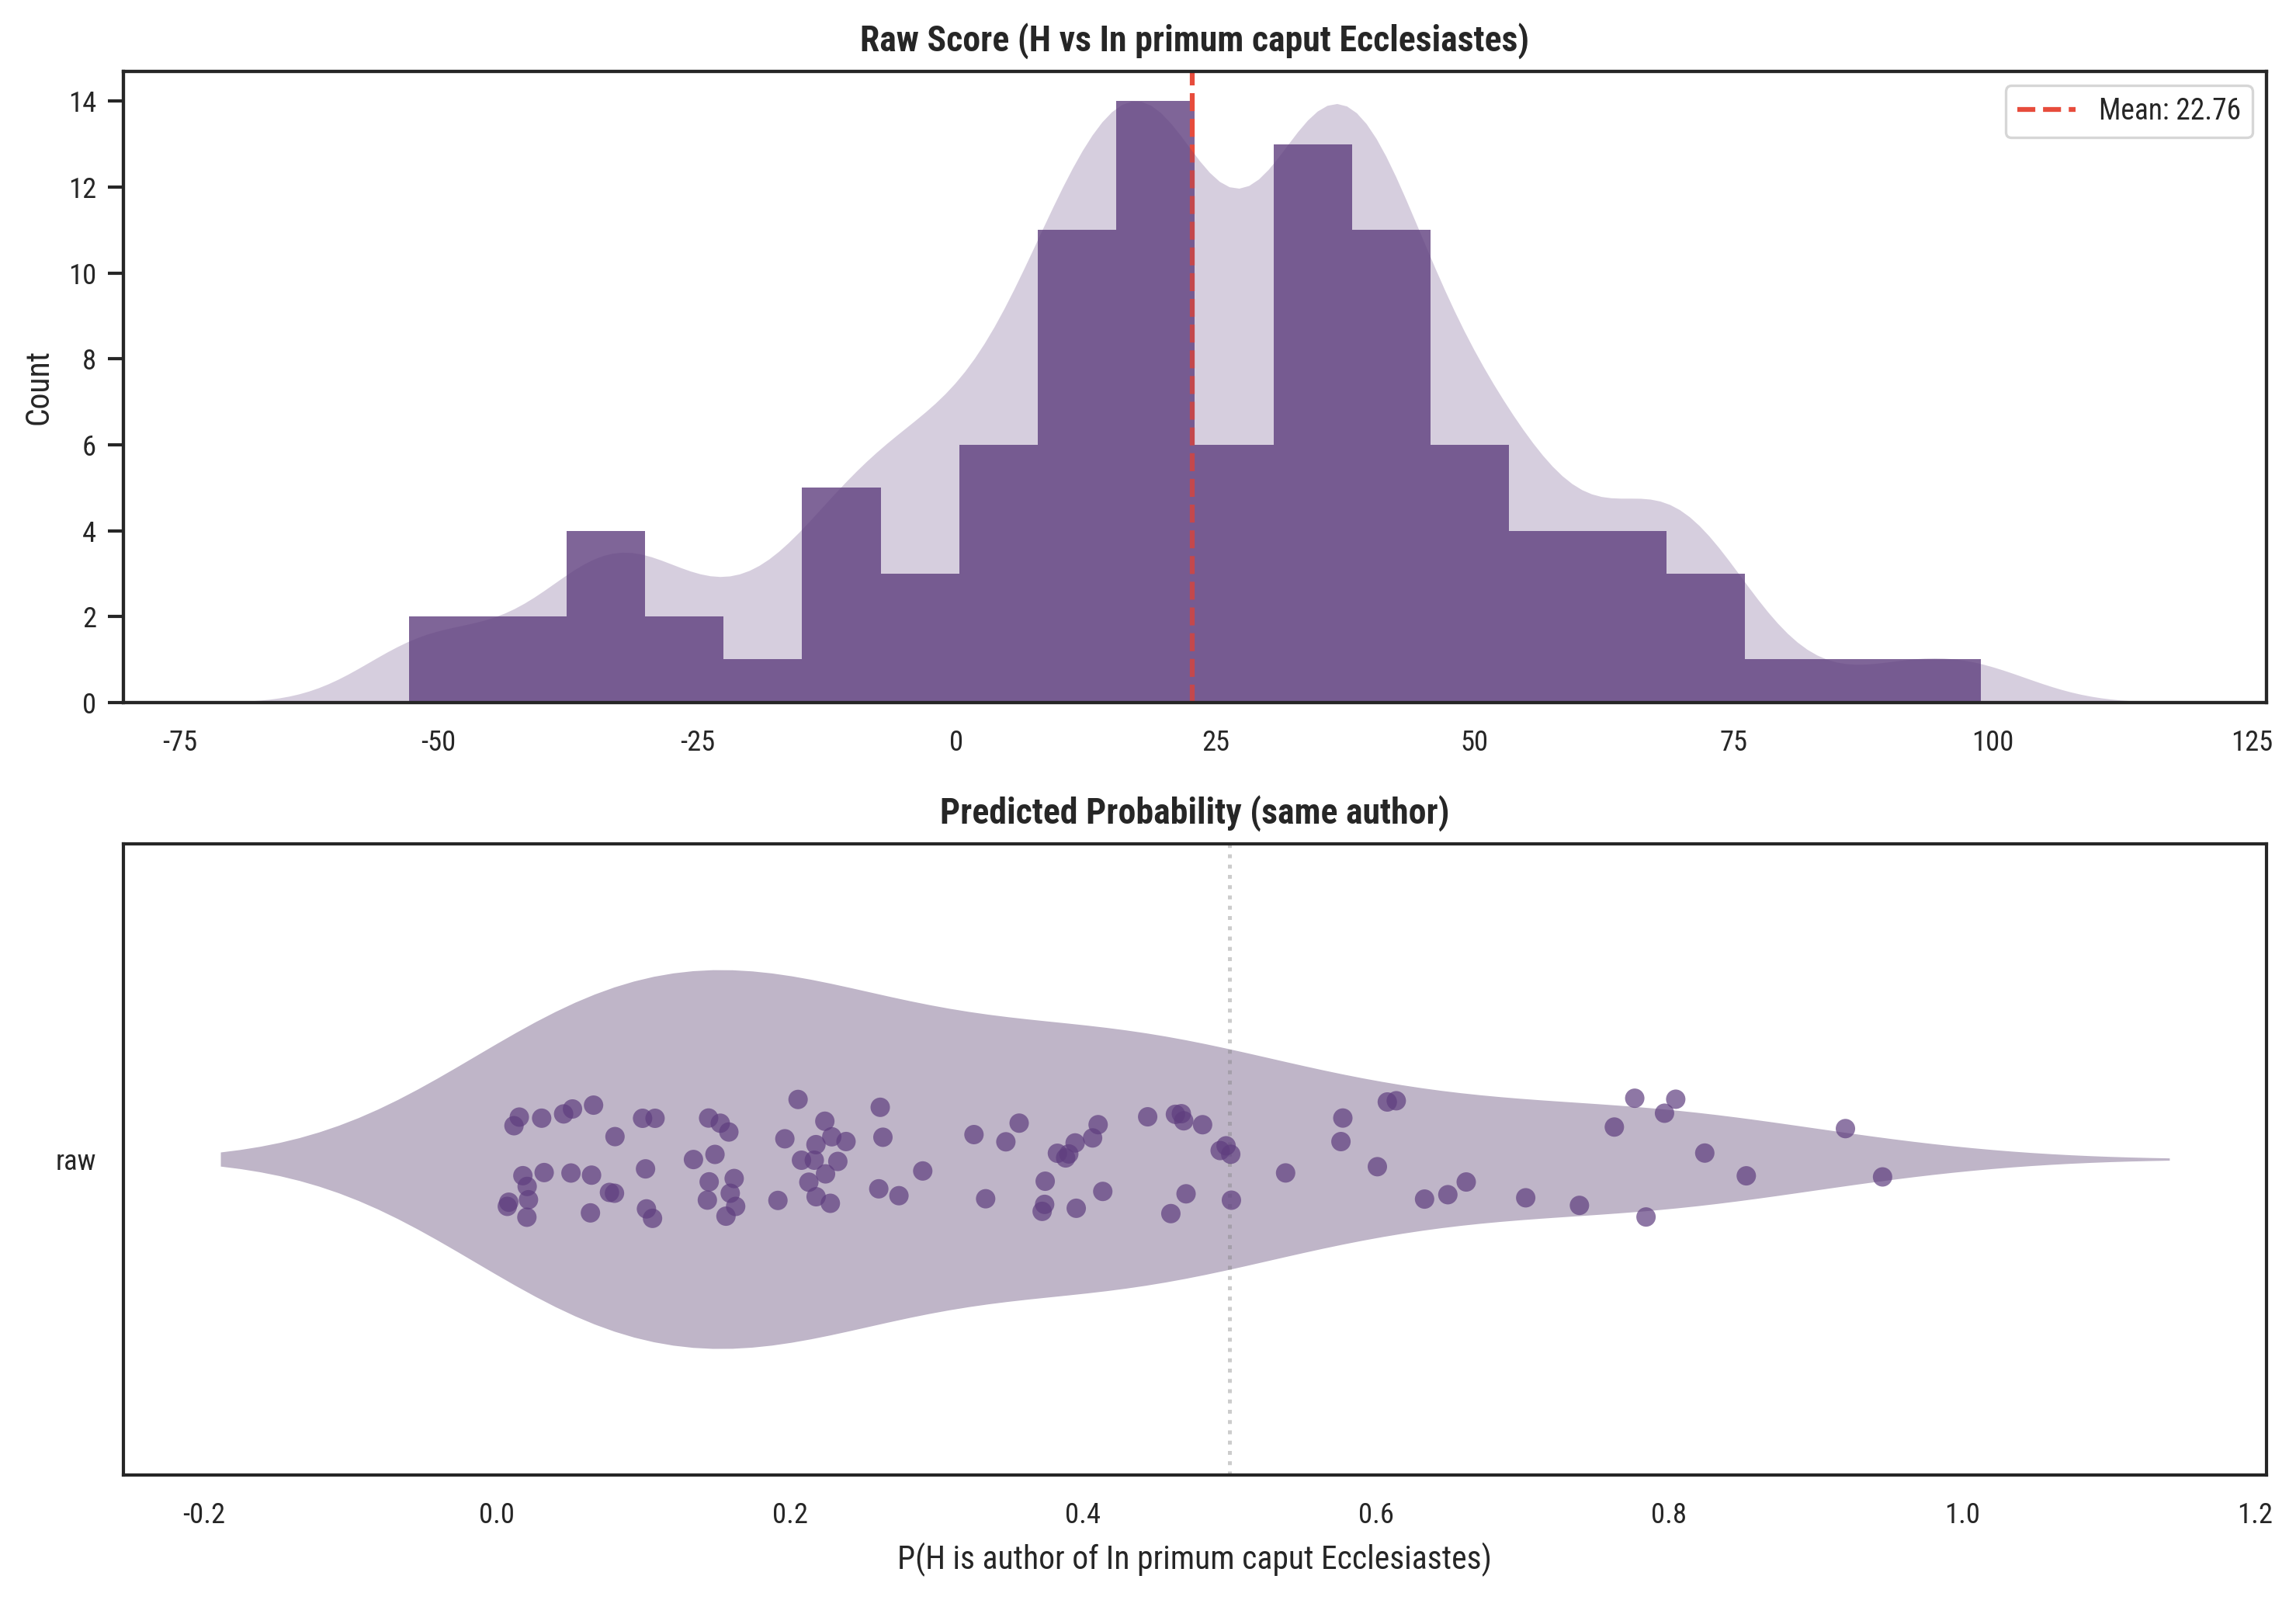

In [13]:
# Visualization: histplot of raw scores + stripplot/violin of probabilities
fig, axes = plt.subplots(2, 1, figsize=(10, 7), dpi=300)

for ax in axes:
    ax.grid(False)

color = "#5f3e7f"

# Row 1: Raw score distribution with KDE overlay
ax = axes[0]
sns.histplot(data=df, x="score", bins=20, ax=ax, color=color, alpha=0.8, linewidth=0)
ax2 = ax.twinx()
sns.kdeplot(
    data=df,
    x="score",
    ax=ax2,
    color=color,
    fill=True,
    linewidth=0,
    alpha=0.25,
    bw_adjust=0.5,
)
ax2.set_yticklabels([])
ax2.set_yticks([])
ax2.set_ylabel("")
ax.set_title("Raw Score (H vs In primum caput Ecclesiastes)", fontweight="bold", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("Count")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
mean_val = df["score"].mean()
ax.axvline(
    mean_val,
    color="#e74c3c",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.2f}",
)
ax.legend(loc="upper right", fontsize=9)

# Row 2: Probability stripplot + violin
ax = axes[1]
ax.grid(False)
df_plot = pd.DataFrame(
    {
        "probability": df["probability"].tolist(),
        "model": ["raw"] * len(df),
    }
)
sns.violinplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    width=0.6,
    inner=None,
    density_norm="width",
    alpha=0.4,
    linewidth=0,
    legend=False,
)
sns.stripplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    size=6,
    jitter=True,
    alpha=0.7,
    legend=False,
)
ax.set_title("Predicted Probability (same author)", fontweight="bold", fontsize=11)
ax.set_xlabel("P(H is author of In primum caput Ecclesiastes)")
ax.set_ylabel("")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## Evaluate Against All Candidates

Run the same 100 evaluations against every author in the shared test corpus. For authors with fewer than 2000 tokens, use their total available token count as `known_size`.

*De ordine mundi* (`X`) is then added as an **analysis-only candidate**. It remains excluded from training and calibration and is added to `kr_corpus` only when `X` itself is the candidate; it therefore does not enter the reference population for comparisons with the other authors.


In [15]:
# Compute known_size for each background author
author_sizes = {}

for author in sorted(test_corpus.get_unique_values("author")):
    author_corpus = test_corpus.filter_by_level("author", author)
    tokens = sum(len(s.text.split()) for s in author_corpus)
    known_size = min(2000, tokens)
    author_sizes[author] = known_size
    print(f"  {author:6s}: {tokens:6d} tokens → known_size={known_size}")

# Add De ordine mundi (X) as an analysis-only candidate
ordine_tokens = sum(len(s.text.split()) for s in ordine_corpus)
author_sizes["X"] = min(2000, ordine_tokens)

print(
    f"  {'X':6s}: {ordine_tokens:6d} tokens → "
    f"known_size={author_sizes['X']} (De ordine; analysis-only holdout)"
)


  AI    :   9861 tokens → known_size=2000
  AeC   :  14745 tokens → known_size=2000
  AeP   :   5806 tokens → known_size=2000
  B     :   1991 tokens → known_size=1991
  BC    :   6994 tokens → known_size=2000
  DC    :   6449 tokens → known_size=2000
  E     :   3326 tokens → known_size=2000
  FB    :  10684 tokens → known_size=2000
  GAp   :   6004 tokens → known_size=2000
  GAr   :  11367 tokens → known_size=2000
  GC    :  12123 tokens → known_size=2000
  GM    :   3379 tokens → known_size=2000
  GP    :  14417 tokens → known_size=2000
  GVS   :   4958 tokens → known_size=2000
  GiP   :   5741 tokens → known_size=2000
  H     :   2829 tokens → known_size=2000
  HA    :   5049 tokens → known_size=2000
  HP    :   7640 tokens → known_size=2000
  IH    :   9514 tokens → known_size=2000
  II    :   8192 tokens → known_size=2000
  M     :   5527 tokens → known_size=2000
  NLC   :   5257 tokens → known_size=2000
  OM    :   8005 tokens → known_size=2000
  OSE   :   3936 tokens → known_si

In [16]:
# Define the per-candidate evaluation function
@ray.remote
def run_evaluation_for_author(
    seed: int,
    known_author: str,
    known_size: int,
    target_tokens: int = 750,
) -> dict:
    """Run one AV evaluation: Ecclesiastes vs a given comparison candidate."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    # Unknown text: random ~750-token sample from In primum caput Ecclesiastes
    q_corpus = sample_corpus_to_token_count(
        ecclesiastes_corpus,
        target_tokens,
        rng,
    )

    # De ordine (X) is a holdout and is added only when it is itself
    # the candidate. It never enters the reference corpus used for
    # evaluations of the background authors.
    if known_author == "X":
        kr_for_candidate = test_plus_ordine
    else:
        kr_for_candidate = test_corpus

    result = av.run_single_av_problem(
        known_entity=known_author,
        q_corpus=q_corpus,
        kr_corpus=kr_for_candidate,
        known_tokens=known_size,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "author": known_author,
        "score": result["score"],
        "known_size": known_size,
    }


In [17]:
N_EVALUATIONS = 100
# Run evaluations for all authors
ray.init()
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

master_rng = np.random.default_rng(123)

all_tasks = []
task_info = []  # (author, seed) for each task

for author, known_size in author_sizes.items():
    for i in range(N_EVALUATIONS):
        seed = master_rng.integers(0, 2**32 - 1)
        all_tasks.append(
            run_evaluation_for_author.remote(seed, author, known_size, TARGET_TOKENS)
        )
        task_info.append(author)

print(f"Created {len(all_tasks)} tasks for {len(author_sizes)} authors")

# Execute all tasks
all_results = []
for _ in tqdm(range(len(all_tasks)), desc="All evaluations"):
    ready, _ = ray.wait(all_tasks, num_returns=1)
    result = ray.get(ready[0])
    all_results.append(result)
    all_tasks.remove(ready[0])

print(f"✓ Completed {len(all_results)} evaluations")
ray.shutdown()

2026-09-14 09:31:29,285	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


(pid=1428) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=1428)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=1427) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=1427)   from pandas.core import (


Created 3900 tasks for 39 authors


All evaluations: 100%|█████████████████████| 3900/3900 [17:47<00:00,  3.65it/s]
(pid=1426) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster]
(pid=1426)   from pandas.core.computation.check import NUMEXPR_INSTALLED [repeated 7x across cluster]
(pid=1430) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed). [repeated 7x across cluster]
(pid=1430)   from pandas.core import ( [repeated 7x across cluster]


✓ Completed 3900 evaluations


In [18]:
# Convert to DataFrame and compute probabilities
df_all = pd.DataFrame(all_results)
df_all["probability"] = model.predict_proba(df_all["score"].values.reshape(-1, 1))[:, 1]

# Summary: mean probability per author
summary = df_all.groupby("author")["probability"].agg(["mean", "std", "count"]).round(4)
summary = summary.sort_values("mean", ascending=False)
print("\n=== Mean Predicted Probability by Author ===")
print(summary)


=== Mean Predicted Probability by Author ===
          mean     std  count
author                       
X       0.9609  0.0922    100
U3      0.8929  0.1249    100
U11     0.7288  0.2652    100
M       0.7063  0.2362    100
HA      0.6607  0.2753    100
SG      0.5891  0.2322    100
FB      0.5846  0.2820    100
B       0.5211  0.2352    100
U7      0.4143  0.2900    100
H       0.3436  0.2501    100
U1      0.2251  0.1623    100
NLC     0.1386  0.1794    100
GiP     0.1367  0.1929    100
OSE     0.1037  0.1509    100
U6      0.0599  0.0981    100
AeC     0.0449  0.0782    100
U9      0.0396  0.0604    100
U2      0.0339  0.0394    100
AI      0.0245  0.0793    100
GM      0.0208  0.0613    100
DC      0.0133  0.0387    100
GC      0.0108  0.0234    100
U4      0.0099  0.0191    100
RT      0.0089  0.0145    100
U8      0.0083  0.0222    100
HP      0.0083  0.0216    100
GVS     0.0075  0.0147    100
GAr     0.0030  0.0067    100
U5      0.0021  0.0045    100
GAp     0.0021  0.0032  

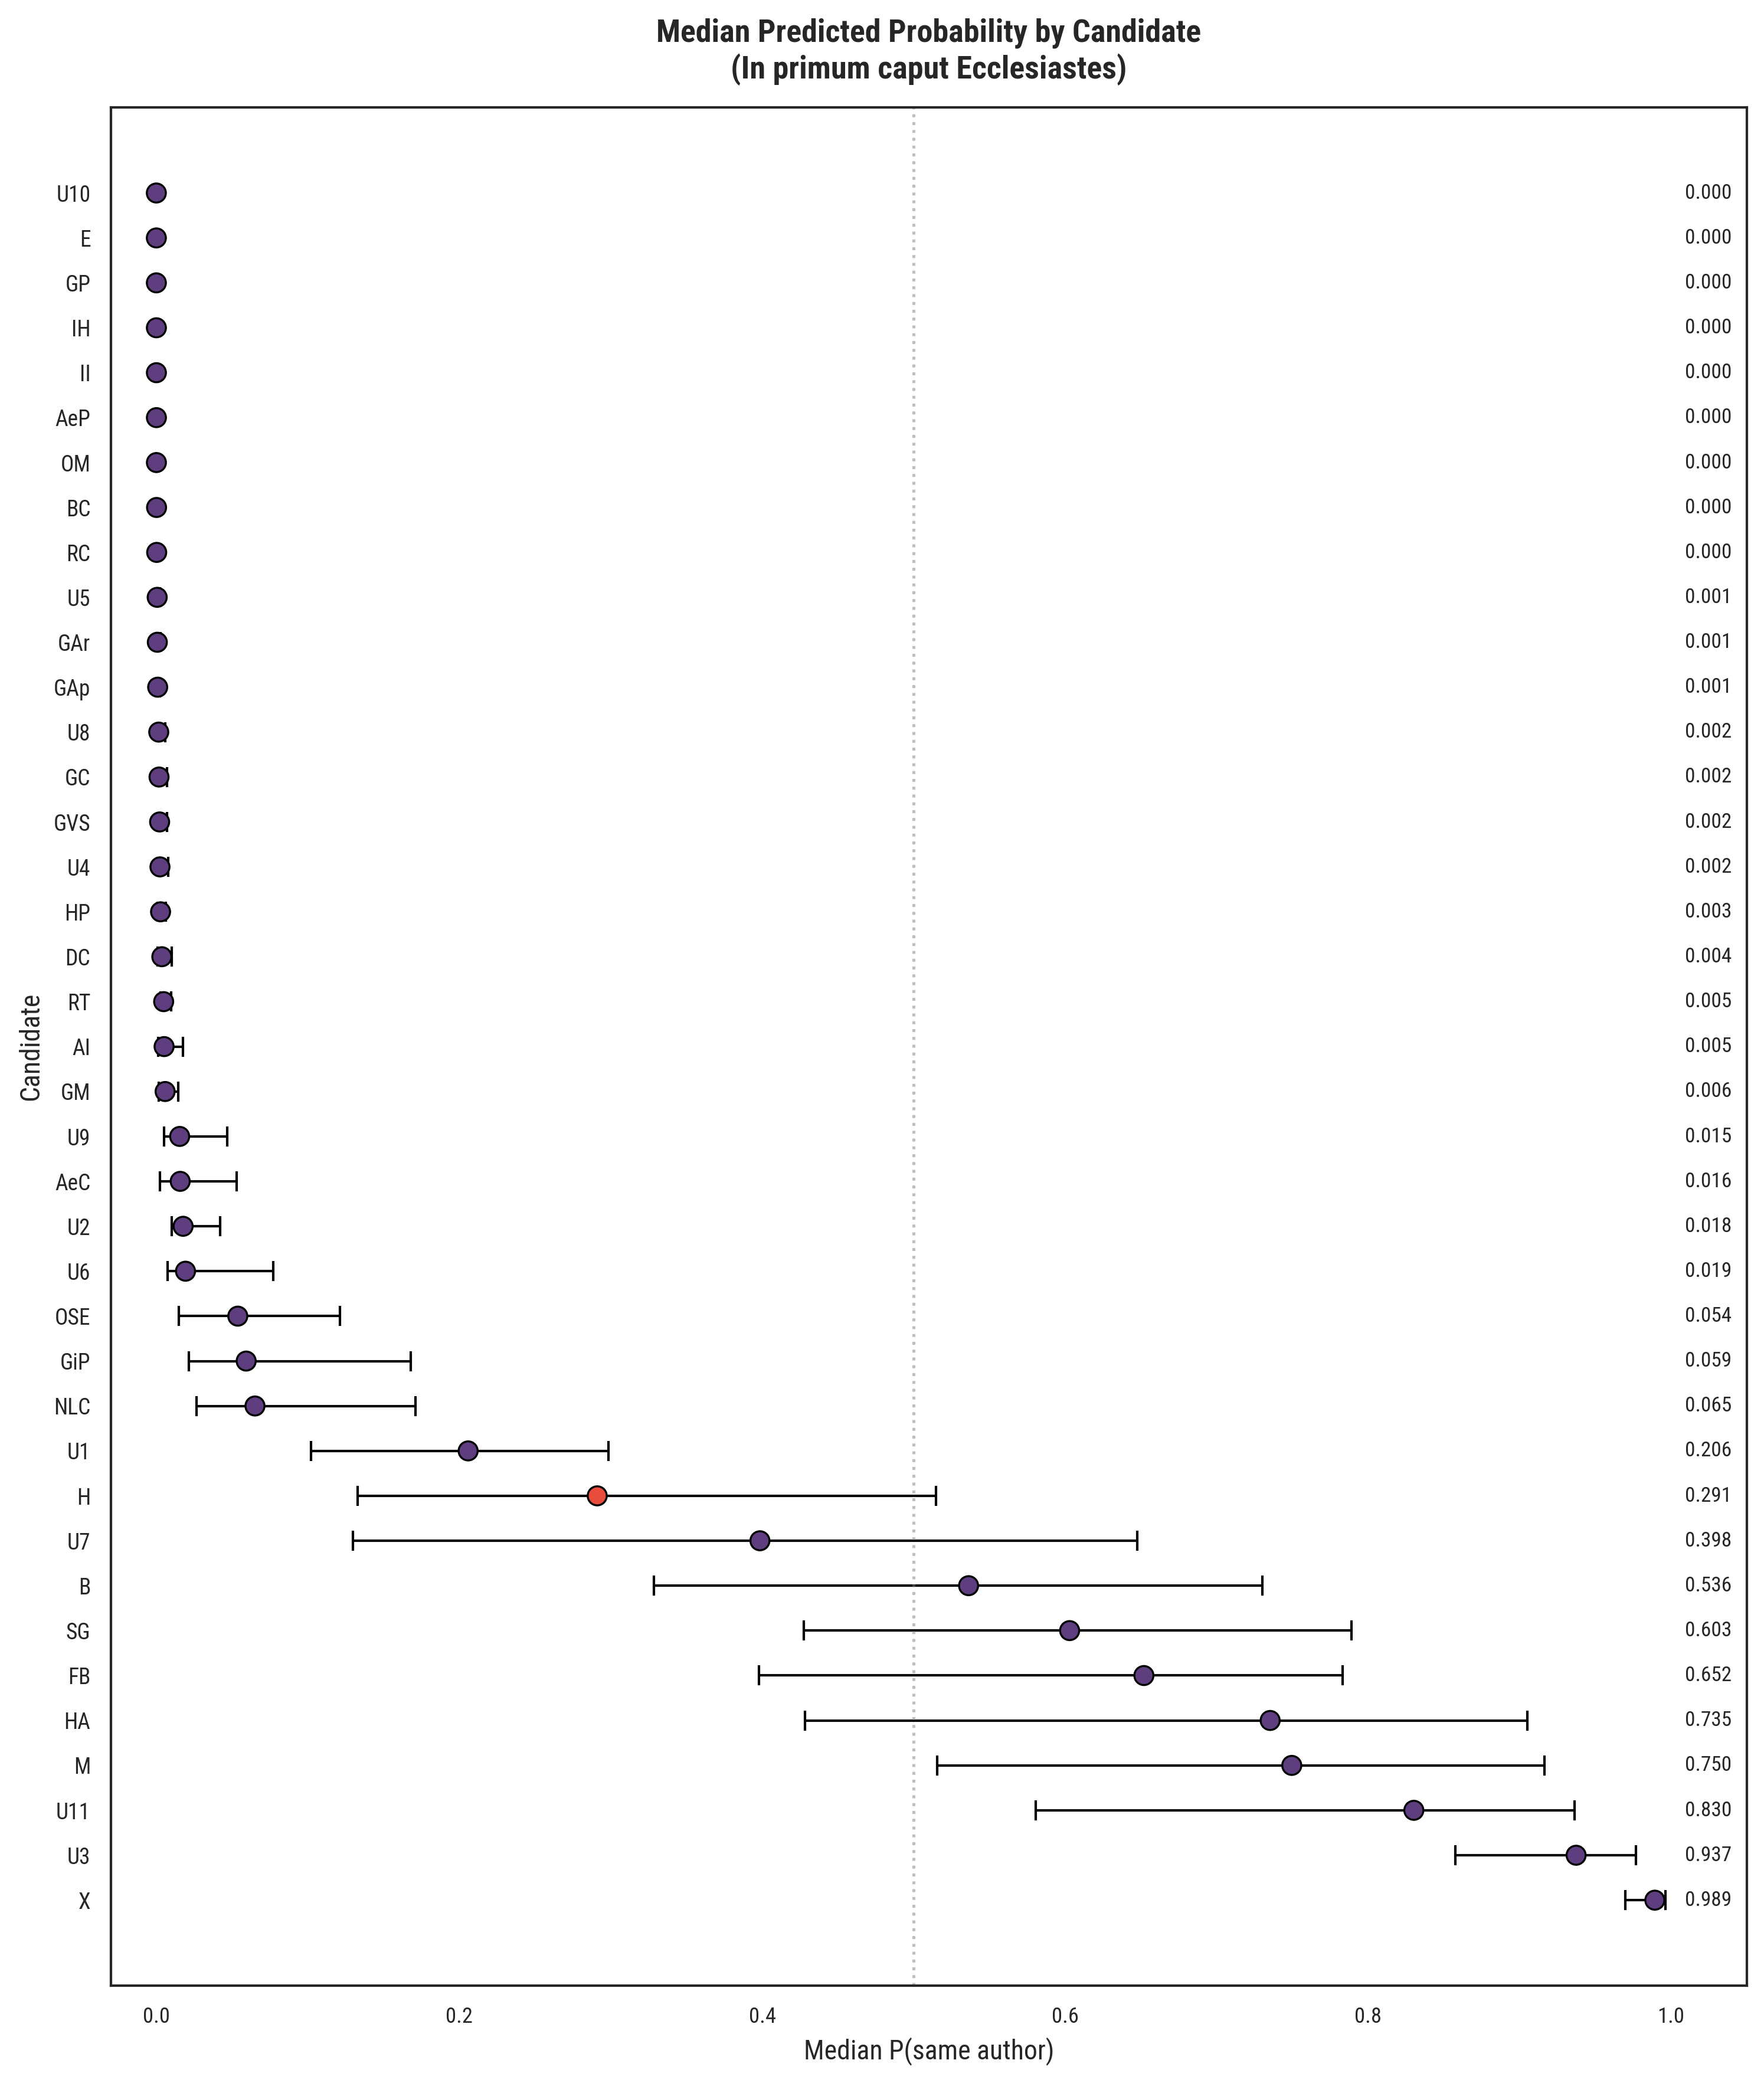

In [20]:
# Visualization: median probability per author with IQR whiskers
import math

# Compute stats per author
stats = df_all.groupby("author")["probability"].agg(
    ["median", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]
)
stats.columns = ["median", "q25", "q75"]
stats = stats.sort_values("median", ascending=True)
authors_ordered = stats.index.tolist()

# Dynamic figure height: more authors = taller figure
fig_height = max(8, 0.32 * len(authors_ordered))
fig, ax = plt.subplots(figsize=(12, fig_height), dpi=300)

ax.grid(False)

# Color: highlight H differently
colors = ["#e74c3c" if a == "H" else "#5f3e7f" for a in authors_ordered]

# IQR whiskers
for i, author in enumerate(authors_ordered):
    row = stats.loc[author]
    ax.plot(
        [row["q25"], row["q75"]],
        [i, i],
        color="black",
        linewidth=1,
        solid_capstyle="round",
        zorder=2,
    )
    for q in [row["q25"], row["q75"]]:
        ax.plot(q, i, "|", color="black", markersize=8, markeredgewidth=1, zorder=3)

# Median dots
ax.scatter(
    stats["median"].values,
    range(len(authors_ordered)),
    c=colors,
    s=60,
    zorder=5,
    edgecolors="black",
    linewidth=0.8,
)

ax.set_yticks(range(len(authors_ordered)))
ax.set_yticklabels(authors_ordered, fontsize=9)

# Put lowest values at the top and highest at the bottom
ax.invert_yaxis()

ax.set_title(
    "Median Predicted Probability by Candidate\n(In primum caput Ecclesiastes)",
    fontweight="bold",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Median P(same author)", fontsize=11)
ax.set_ylabel("Candidate", fontsize=11)

# Reference line at 0.5
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.5)

# Leave extra room on the right for value labels
ax.set_xlim(-0.03, 1.05)
ax.set_xticks(np.arange(0, 1.01, 0.2))

# Add value labels on the right side of the plot
for i, val in enumerate(stats["median"].values):
    ax.text(
        1.04,
        i,
        f"{val:.3f}",
        va="center",
        ha="right",
        fontsize=8.5,
    )

# Improve margins
plt.subplots_adjust(left=0.18, right=0.95, top=0.92, bottom=0.07)
plt.savefig(f"Median_probability.png", dpi=300, bbox_inches="tight")
plt.show()